# 02 · Clustering bike trips (Part A)

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- Wrote and ran all code: feature design, PCA, choice of K, KMeans, comparison with Ward and GMM, cluster profiles, sensitivity check, saved labels.
- Chose K = 6 from the metrics in section 3.

**Not done by Claude**
- No interpretation of any result and no written findings. Every `_Team notes:_` cell is left empty for the team.
- Cluster names or labels in words: none are given in the notebook.
- The team's own files (`data-cleanup.ipynb`, `Scratchpad.ipynb`, `FINDINGS.md`) were not edited.
- The cluster descriptions given in chat are Claude's reading of the numbers and are deliberately not written here.

_Team notes:_

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
import bikeshare_common as bc

bc.set_style()
pd.set_option("display.width", 200)
RNG = np.random.default_rng(42)
t = bc.load_clean("trips_clean")
t.shape

(1161376, 42)

## 1. Features

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- Chose 8 features: log duration, log distance, speed, hour sin/cos, weekend, start centrality relative to the city's median trip, radial movement (clipped ±10 km).

**Not done by Claude**
- E-bike, free-floating, weather and month were left out of the clustering features. They are only used afterwards to describe the clusters.
- Cargo was dropped because it is always 0 in the trip file.

In [2]:
city_med = t.groupby("city_id").dist_centre_start_km.transform("median")
X = pd.DataFrame({
    "log_duration": np.log(t.duration / 60),
    "log_distance": np.log(t.distance),
    "speed_kmh": t.speed_kmh,
    "hour_sin": t.hour_sin,
    "hour_cos": t.hour_cos,
    "weekend": t.weekend.astype(float),
    # >0 = starts closer to the centre than the city's typical trip
    "centrality_start": -np.log((t.dist_centre_start_km + 0.1) / (city_med + 0.1)),
    # >0 = moves away from the centre
    "radial_km": (t.dist_centre_end_km - t.dist_centre_start_km).clip(-10, 10),
})
X.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
log_duration,1161376.0,2.61,0.80,0.70,2.08,2.48,3.00,6.17
log_distance,1161376.0,7.24,0.71,3.91,6.79,7.21,7.71,9.90
speed_kmh,1161376.0,7.32,3.30,0.25,5.16,7.54,9.61,15.05
hour_sin,1161376.0,-0.25,0.70,-1.00,-0.87,-0.50,0.26,1.00
hour_cos,1161376.0,-0.30,0.60,-1.00,-0.87,-0.50,0.00,1.00
weekend,1161376.0,0.23,0.42,0.00,0.00,0.00,0.00,1.00
centrality_start,1161376.0,0.06,0.67,-7.78,-0.32,-0.00,0.43,3.38
radial_km,1161376.0,0.19,1.64,-10.00,-0.67,0.12,0.91,10.00


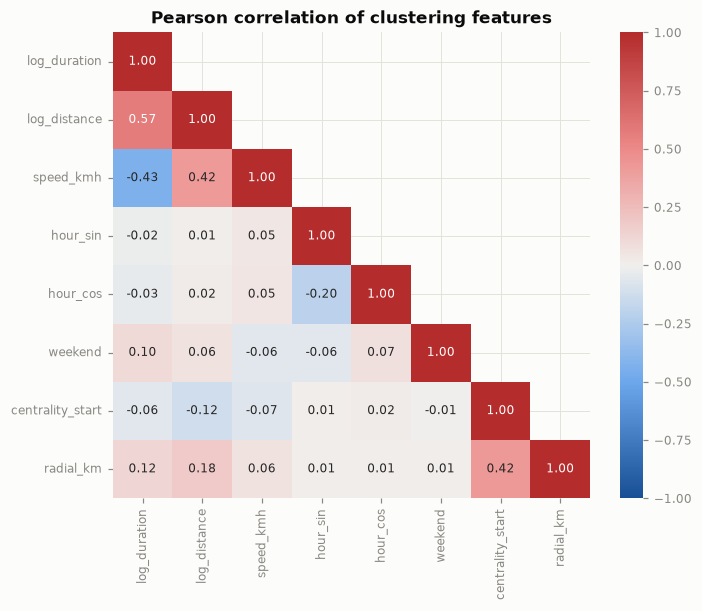

In [3]:
fig, ax = plt.subplots(figsize=(7, 5.5))
c = X.corr()
sns.heatmap(c, cmap=bc.DIV, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 8}, ax=ax,
            mask=np.triu(np.ones_like(c, bool), k=1))
ax.set_title("Pearson correlation of clustering features")
plt.show()

In [4]:
scaler = StandardScaler().fit(X)
Z = scaler.transform(X)

## 2. PCA

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- PCA on the standardised features: scree plot, loadings, correlation circles PC1–PC2 and PC3–PC4.

**Not done by Claude**
- KMeans runs on all 8 standardised features, not on the PCA scores. Here PCA is only used for interpretation.
- No rotation (e.g. varimax) and no MCA/FAMD.

In [5]:
pca = PCA().fit(Z)
ev = pd.DataFrame({"eigenvalue": pca.explained_variance_, "explained": pca.explained_variance_ratio_,
                   "cumulative": pca.explained_variance_ratio_.cumsum()}, index=[f"PC{i+1}" for i in range(Z.shape[1])])
ev.round(3)

,eigenvalue,explained,cumulative
PC1,1.663,0.208,0.208
PC2,1.413,0.177,0.385
PC3,1.412,0.176,0.561
PC4,1.230,0.154,0.715
PC5,0.940,0.117,0.832
PC6,0.788,0.098,0.931
PC7,0.504,0.063,0.994
PC8,0.051,0.006,1.000


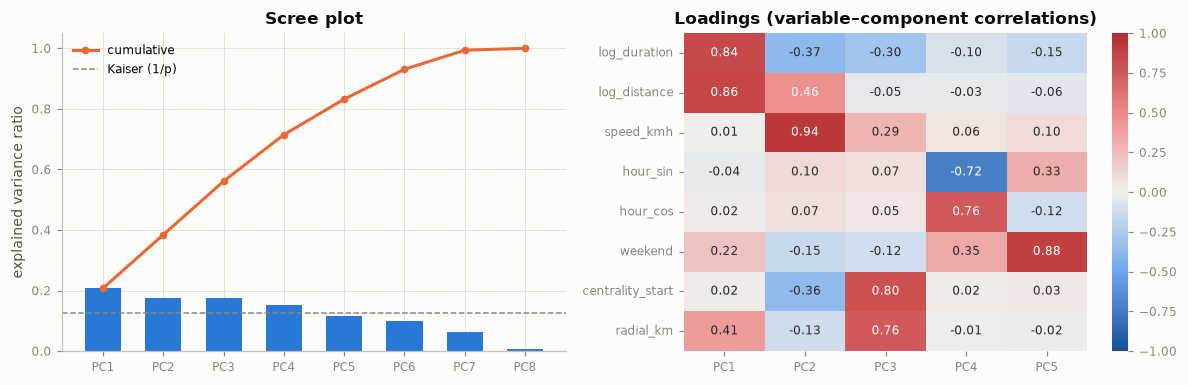

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].bar(ev.index, ev.explained, color=bc.SERIES[0], width=0.6)
ax[0].plot(ev.index, ev.cumulative, color=bc.SERIES[1], marker="o", ms=4, label="cumulative")
ax[0].axhline(1 / Z.shape[1], color=bc.GREY, ls="--", lw=1, label="Kaiser (1/p)")
ax[0].set(title="Scree plot", ylabel="explained variance ratio")
ax[0].legend()
load = pd.DataFrame(pca.components_[:5].T * np.sqrt(pca.explained_variance_[:5]), index=X.columns,
                    columns=[f"PC{i+1}" for i in range(5)])
sns.heatmap(load, cmap=bc.DIV, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 8}, ax=ax[1])
ax[1].set_title("Loadings (variable–component correlations)")
plt.tight_layout()
plt.show()

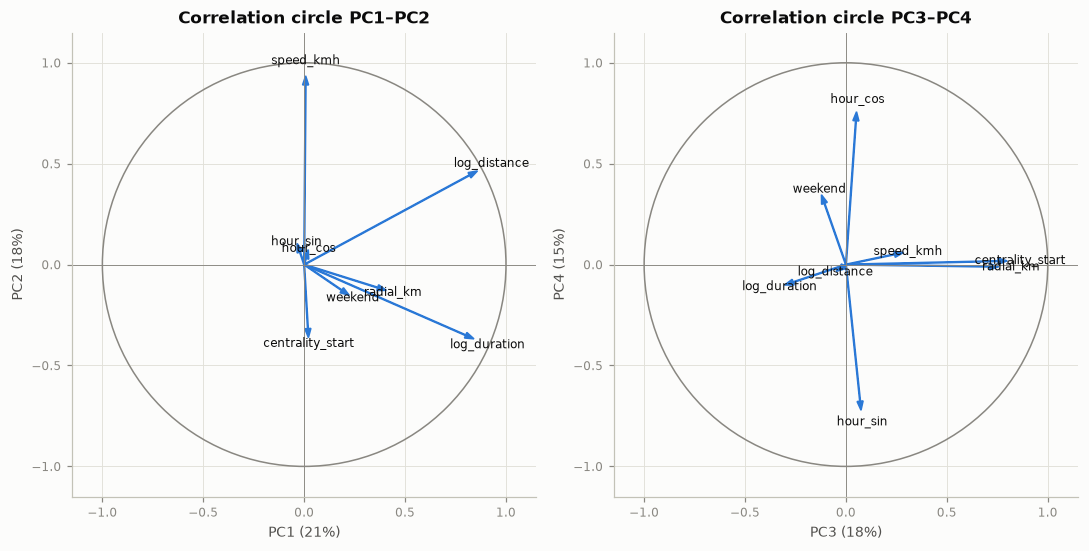

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, (a, b) in zip(axes, [(0, 1), (2, 3)]):
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, color=bc.GREY, lw=1))
    for v in X.columns:
        x, y = load.iloc[:, a][v], load.iloc[:, b][v]
        ax.arrow(0, 0, x, y, color=bc.SERIES[0], width=0.004, head_width=0.03, length_includes_head=True)
        ax.text(x * 1.08, y * 1.08, v, fontsize=8, ha="center", va="center", color="#0b0b0b")
    ax.set(xlim=(-1.15, 1.15), ylim=(-1.15, 1.15), aspect="equal",
           xlabel=f"PC{a+1} ({ev.explained.iloc[a]:.0%})", ylabel=f"PC{b+1} ({ev.explained.iloc[b]:.0%})",
           title=f"Correlation circle PC{a+1}–PC{b+1}")
    ax.axhline(0, color=bc.GREY, lw=.6)
    ax.axvline(0, color=bc.GREY, lw=.6)
plt.tight_layout()
plt.show()

_Team notes:_

## 3. Choosing the number of clusters

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- KMeans for k = 2..10 on all 1.16M trips. Silhouette, Davies–Bouldin and Calinski–Harabasz on a 30k sample.
- Bootstrap stability for k = 4..8: 8 fits on 300k resamples, ARI compared on a fixed 50k reference set.
- GMM BIC on a 150k sample. Final KMeans K = 6 (n_init = 10), ids ordered by mean duration. ARI against Ward and GMM on a 15k sample.

**Not done by Claude**
- Silhouette is not computed on all trips, and Ward/GMM are not fitted on the full data (too costly).
- MiniBatchKMeans was tried first and dropped for instability. That run is not in the notebook.
- The choice of K = 6 is a judgement call the team should check against the metrics.

In [8]:
# all 8 standardised features; PCA kept for interpretation (last PC is 0.6% → near-redundant duration/distance/speed)
sidx = RNG.choice(len(Z), 30_000, replace=False)
rows = []
models = {}
for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=0, n_init=5).fit(Z)
    models[k] = km
    lab = km.labels_[sidx]
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(Z[sidx], lab),
                 "davies_bouldin": davies_bouldin_score(Z[sidx], lab),
                 "calinski_harabasz": calinski_harabasz_score(Z[sidx], lab),
                 "smallest_cluster_share": np.bincount(km.labels_).min() / len(Z)})
sel = pd.DataFrame(rows).set_index("k")
sel.round(3)

,inertia,silhouette,davies_bouldin,calinski_harabasz,smallest_cluster_share
k,,,,,
2,8087676.133,0.143,2.500,4430.564,0.435
3,7176692.963,0.148,2.122,4397.962,0.216
4,6419922.396,0.155,1.830,4487.592,0.156
5,5794816.543,0.163,1.652,4500.533,0.126
6,5277529.778,0.169,1.509,4557.464,0.113
7,4977802.000,0.155,1.488,4309.671,0.107
8,4756478.269,0.167,1.557,4074.438,0.090
9,4556394.261,0.159,1.542,3890.712,0.080
10,4364813.125,0.162,1.521,3750.884,0.069


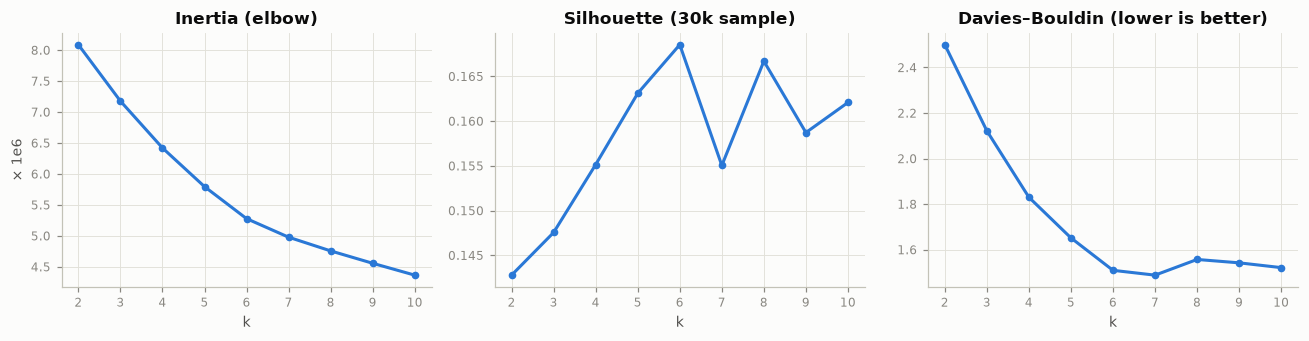

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
ax[0].plot(sel.index, sel.inertia / 1e6, marker="o", ms=4)
ax[0].set(title="Inertia (elbow)", xlabel="k", ylabel="× 1e6")
ax[1].plot(sel.index, sel.silhouette, marker="o", ms=4)
ax[1].set(title="Silhouette (30k sample)", xlabel="k")
ax[2].plot(sel.index, sel.davies_bouldin, marker="o", ms=4)
ax[2].set(title="Davies–Bouldin (lower is better)", xlabel="k")
plt.tight_layout()
plt.show()

In [10]:
# stability: refit on bootstrap samples, compare labels on a fixed reference set
ref = Z[RNG.choice(len(Z), 50_000, replace=False)]
stab = {}
for k in range(4, 9):
    labs = []
    for b in range(8):
        boot = Z[RNG.choice(len(Z), 300_000, replace=True)]
        labs.append(KMeans(n_clusters=k, random_state=b, n_init=10).fit(boot).predict(ref))
    aris = [adjusted_rand_score(labs[i], labs[j]) for i in range(len(labs)) for j in range(i + 1, len(labs))]
    stab[k] = {"mean_ARI": np.mean(aris), "min_ARI": np.min(aris)}
pd.DataFrame(stab).T.round(3)

,mean_ARI,min_ARI
4,0.571,0.339
5,0.943,0.873
6,0.989,0.983
7,0.979,0.967
8,0.978,0.966


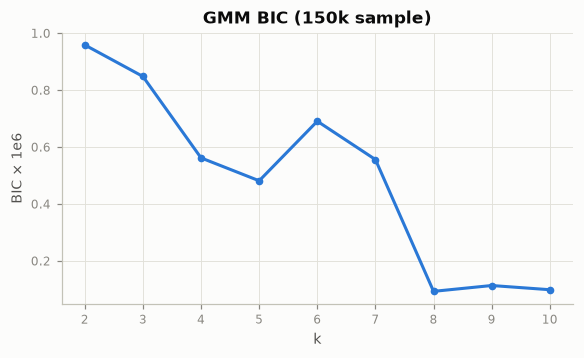

In [11]:
# Gaussian mixture as a model-based alternative (BIC)
gsub = Z[RNG.choice(len(Z), 150_000, replace=False)]
bic = {k: GaussianMixture(k, covariance_type="full", random_state=0, n_init=2).fit(gsub).bic(gsub) for k in range(2, 11)}
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(list(bic), np.array(list(bic.values())) / 1e6, marker="o", ms=4)
ax.set(title="GMM BIC (150k sample)", xlabel="k", ylabel="BIC × 1e6")
plt.show()

In [12]:
K = 6
km = KMeans(n_clusters=K, random_state=0, n_init=10).fit(Z)
raw_lab = km.labels_
# order clusters by median duration so ids are stable and readable
order = pd.Series(raw_lab).groupby(raw_lab).apply(lambda i: t.duration.values[i.index].mean()).sort_values().index
remap = {old: new for new, old in enumerate(order)}
t["trip_cluster"] = pd.Series(raw_lab).map(remap).values
t.trip_cluster.value_counts(normalize=True).sort_index().round(3)

trip_cluster
0    0.227
1    0.243
2    0.165
3    0.129
4    0.122
5    0.113
Name: proportion, dtype: float64

In [13]:
# agreement with other algorithms on a sample
s_idx = RNG.choice(len(Z), 15_000, replace=False)
ward = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(Z[s_idx])
gmm = GaussianMixture(K, covariance_type="full", random_state=0, n_init=2).fit(gsub).predict(Z[s_idx])
pd.Series({"ARI KMeans vs Ward": adjusted_rand_score(t.trip_cluster.values[s_idx], ward),
           "ARI KMeans vs GMM": adjusted_rand_score(t.trip_cluster.values[s_idx], gmm),
           "silhouette (K)": silhouette_score(Z[s_idx], t.trip_cluster.values[s_idx])}).round(3)

ARI KMeans vs Ward    0.433
ARI KMeans vs GMM     0.402
silhouette (K)        0.169
dtype: float64

_Team notes:_

## 4. Cluster profiles

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- Profile table, standardised centroids, start-hour curves, distance–duration and PC1–PC2 scatters, monthly mix, weather context, country mix, Cramér's V.

**Not done by Claude**
- No naming or interpretation of the clusters.

In [14]:
t["radial_km"] = X.radial_km.values
prof = t.groupby("trip_cluster").agg(
    share=("bike_id", lambda x: len(x) / len(t)),
    median_min=("duration", lambda x: x.median() / 60),
    median_km=("distance", lambda x: x.median() / 1000),
    median_speed=("speed_kmh", "median"),
    weekend=("weekend", "mean"),
    peak_7_9=("hour", lambda h: h.between(7, 9).mean()),
    peak_16_18=("hour", lambda h: h.between(16, 18).mean()),
    night_22_5=("hour", lambda h: ((h >= 22) | (h <= 5)).mean()),
    start_dist_centre_km=("dist_centre_start_km", "median"),
    radial_km=("radial_km", "median"),
    ebike=("ebike", "mean"),
    start_free=("start_free", "mean"), end_free=("end_free", "mean"),
    temp=("temperature_2m", "mean"), rain_hour=("precipitation", lambda p: (p > 0.1).mean()),
)
prof.round(3)

,share,median_min,median_km,median_speed,weekend,peak_7_9,peak_16_18,night_22_5,start_dist_centre_km,radial_km,ebike,start_free,end_free,temp,rain_hour
trip_cluster,,,,,,,,,,,,,,,
0,0.227,8.0,0.995,7.570,0.000,0.371,0.000,0.042,1.035,0.082,0.122,0.087,0.119,12.500,0.081
1,0.243,9.0,1.076,7.370,0.000,0.000,0.448,0.133,1.045,0.131,0.149,0.076,0.111,14.911,0.079
2,0.165,11.0,1.267,7.173,1.000,0.074,0.220,0.175,1.259,0.100,0.137,0.076,0.109,15.177,0.076
3,0.129,17.0,2.653,9.666,0.133,0.123,0.254,0.078,3.151,-1.802,0.172,0.083,0.088,14.691,0.081
4,0.122,20.0,3.224,9.993,0.183,0.140,0.219,0.113,1.007,2.500,0.245,0.048,0.093,14.981,0.082
5,0.113,51.0,1.352,1.591,0.219,0.127,0.227,0.054,1.453,0.086,0.146,0.084,0.089,15.560,0.079


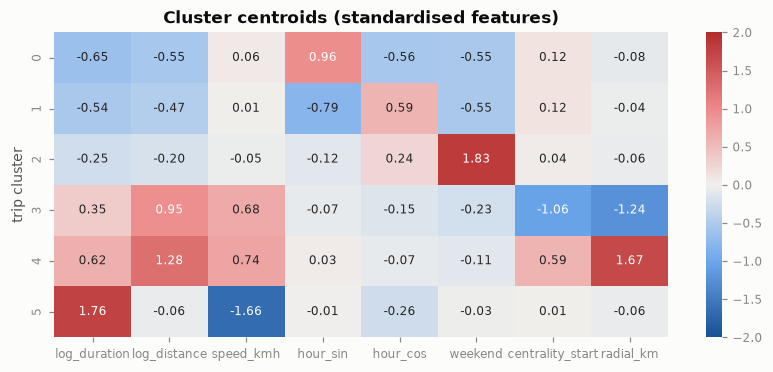

In [15]:
# standardised centroids (z-scores) for a compact view of what separates the clusters
cent = pd.DataFrame(Z).groupby(t.trip_cluster.values).mean()
cent.columns = X.columns
fig, ax = plt.subplots(figsize=(9, 3.6))
sns.heatmap(cent, cmap=bc.DIV, center=0, vmin=-2, vmax=2, annot=True, fmt=".2f", annot_kws={"size": 8}, ax=ax)
ax.set(title="Cluster centroids (standardised features)", ylabel="trip cluster")
plt.show()

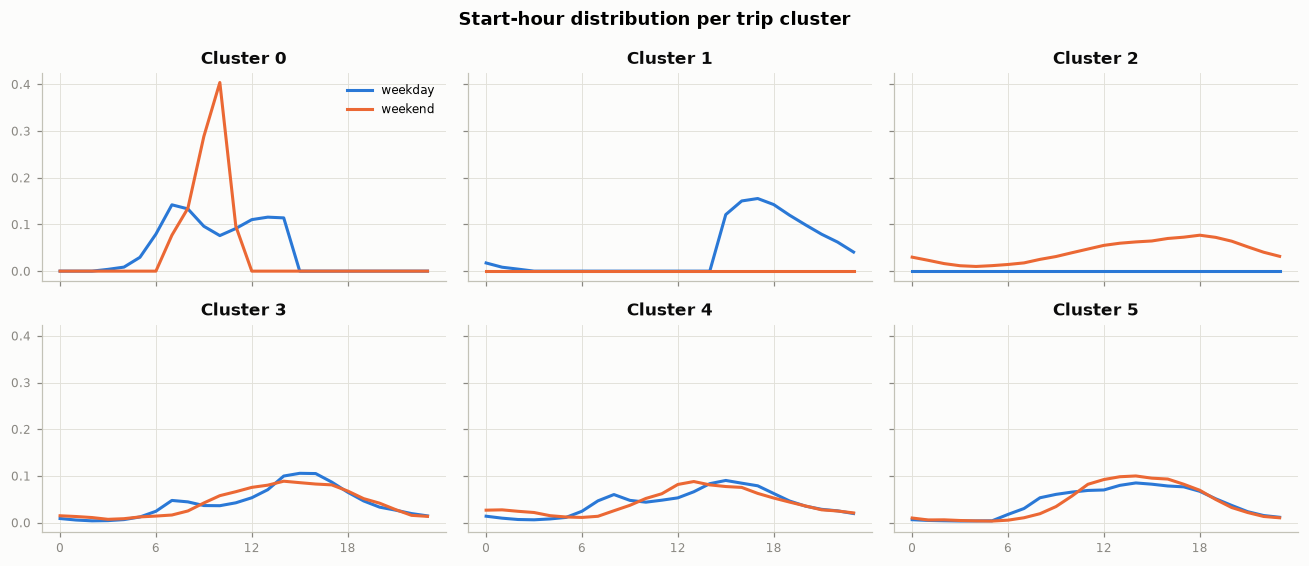

In [16]:
hp = t.groupby(["trip_cluster", "weekend", "hour"]).size()
hp = hp / hp.groupby(level=[0, 1]).transform("sum")
hp = hp.reindex(pd.MultiIndex.from_product([range(K), [0, 1], range(24)]), fill_value=0)
fig, axes = plt.subplots(2, (K + 1) // 2, figsize=(12, 5.2), sharex=True, sharey=True)
for c, ax in zip(range(K), axes.flat):
    ax.plot(range(24), hp.loc[(c, 0)].values, label="weekday", color=bc.SERIES[0])
    ax.plot(range(24), hp.loc[(c, 1)].values, label="weekend", color=bc.SERIES[1])
    ax.set(title=f"Cluster {c}", xticks=range(0, 24, 6))
axes.flat[0].legend()
fig.suptitle("Start-hour distribution per trip cluster", fontweight="bold")
plt.tight_layout()
plt.show()

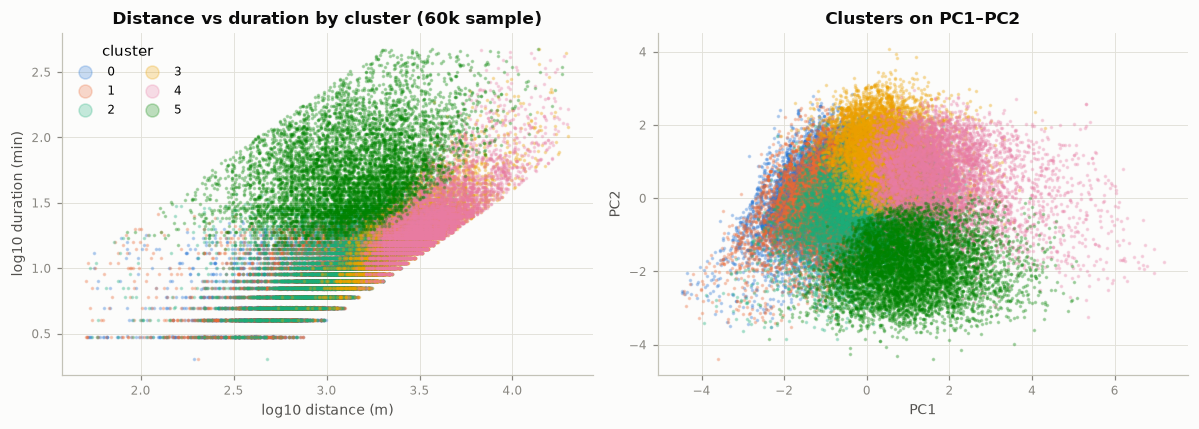

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
samp = t.sample(60_000, random_state=1)
for c in range(K):
    d = samp[samp.trip_cluster == c]
    ax[0].scatter(np.log10(d.distance), np.log10(d.duration / 60), s=2, alpha=.25, color=bc.SERIES[c], label=f"{c}")
ax[0].set(title="Distance vs duration by cluster (60k sample)", xlabel="log10 distance (m)", ylabel="log10 duration (min)")
ax[0].legend(markerscale=6, title="cluster", ncol=2)
scores = pca.transform(scaler.transform(X.loc[samp.index]))
for c in range(K):
    m = samp.trip_cluster.values == c
    ax[1].scatter(scores[m, 0], scores[m, 1], s=2, alpha=.25, color=bc.SERIES[c])
ax[1].set(title="Clusters on PC1–PC2", xlabel="PC1", ylabel="PC2")
plt.tight_layout()
plt.show()

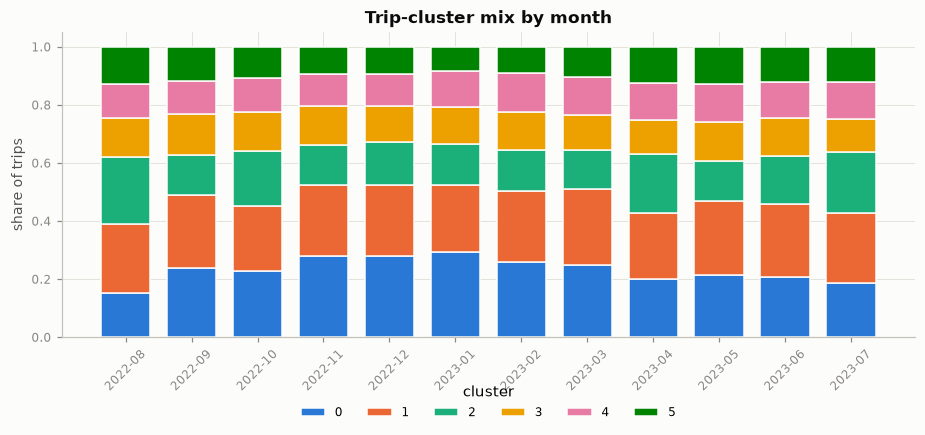

In [18]:
# monthly mix: does the cluster composition change with season?
mm = pd.crosstab(t.start_local.dt.to_period("M"), t.trip_cluster, normalize="index")
fig, ax = plt.subplots(figsize=(10, 3.6))
bottom = np.zeros(len(mm))
for c in range(K):
    ax.bar(mm.index.astype(str), mm[c], bottom=bottom, color=bc.SERIES[c], label=f"{c}", width=0.75,
           edgecolor="#fcfcfb", linewidth=1)
    bottom += mm[c].values
ax.set(title="Trip-cluster mix by month", ylabel="share of trips")
ax.legend(title="cluster", ncol=K, loc="upper center", bbox_to_anchor=(.5, -.12))
plt.xticks(rotation=45)
plt.show()

In [19]:
# weather sensitivity: share of each cluster on warm-dry vs cold-or-wet hours
t["weather_ctx"] = np.where((t.temperature_2m >= 15) & (t.precipitation < 0.1), "warm & dry",
                   np.where((t.temperature_2m < 8) | (t.precipitation >= 0.5), "cold or wet", "mild"))
pd.crosstab(t.weather_ctx, t.trip_cluster, normalize="index").round(3)

trip_cluster,0,1,2,3,4,5
weather_ctx,,,,,,
cold or wet,0.306,0.228,0.143,0.121,0.113,0.088
mild,0.245,0.235,0.160,0.132,0.119,0.109
warm & dry,0.172,0.257,0.182,0.131,0.130,0.129


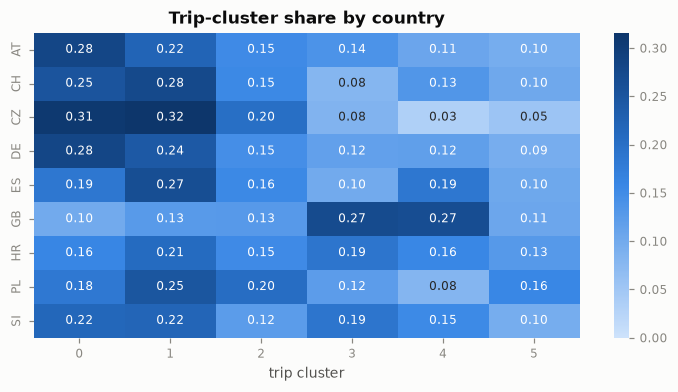

In [20]:
# country composition (countries with > 20k trips)
big = t.country.value_counts()
big = big[big > 20_000].index
cc = pd.crosstab(t.loc[t.country.isin(big), "country"], t.loc[t.country.isin(big), "trip_cluster"], normalize="index")
fig, ax = plt.subplots(figsize=(8, 3.6))
sns.heatmap(cc, cmap=bc.SEQ, annot=True, fmt=".2f", annot_kws={"size": 8}, ax=ax, vmin=0)
ax.set(title="Trip-cluster share by country", xlabel="trip cluster", ylabel="")
plt.show()

In [21]:
# association strength of cluster with categorical context variables (Cramér's V)
from scipy.stats import chi2_contingency


def cramers_v(a, b):
    ct = pd.crosstab(a, b)
    chi2 = chi2_contingency(ct)[0]
    return np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))


pd.Series({v: cramers_v(t.trip_cluster, t[v]) for v in ["ebike", "start_free", "end_free", "country", "weather_ctx", "month"]},
          name="Cramér's V").round(3).to_frame()

,Cramér's V
ebike,0.101
start_free,0.044
end_free,0.039
country,0.123
weather_ctx,0.092
month,0.051


_Team notes:_

## 5. Sensitivity: clustering without time-of-day features

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- Re-ran KMeans (k = 2..8) without hour and weekend features; ARI against the main clustering.

**Not done by Claude**
- No other sensitivity checks (e.g. other scalings, dropping speed).

In [22]:
shape_cols = ["log_duration", "log_distance", "speed_kmh", "centrality_start", "radial_km"]
Zs = StandardScaler().fit_transform(X[shape_cols])
ks = {}
for k in range(2, 9):
    m = KMeans(n_clusters=k, random_state=0, n_init=5).fit(Zs)
    ks[k] = {"silhouette": silhouette_score(Zs[sidx], m.labels_[sidx]), "davies_bouldin": davies_bouldin_score(Zs[sidx], m.labels_[sidx]),
             "ARI vs main (K)": adjusted_rand_score(t.trip_cluster.values[sidx], m.labels_[sidx])}
pd.DataFrame(ks).T.round(3)

,silhouette,davies_bouldin,ARI vs main (K)
2,0.220,1.791,0.172
3,0.246,1.435,0.240
4,0.264,1.155,0.317
5,0.225,1.253,0.282
6,0.224,1.193,0.275
7,0.227,1.192,0.261
8,0.221,1.200,0.229


_Team notes:_

## 6. Save labels

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- Saved `trip_clusters.pkl` (used in notebook 03).

In [23]:
out = t[["bike_id", "time_start", "city_id", "station_id_start", "station_id_end", "trip_cluster"]]
bc.save_clean(out, "trip_clusters")
out.shape

(1161376, 6)